# Explainable AI-Based Network Traffic Attack Detection and Classification System

## 0. Setup

In [1]:
!pip install xgboost imbalanced-learn shap --quiet

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.model_selection import (cross_val_score, StratifiedKFold,
                                      StratifiedGroupKFold, cross_val_predict, RandomizedSearchCV)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              classification_report, confusion_matrix, balanced_accuracy_score, roc_auc_score, average_precision_score)
from imblearn.over_sampling import SMOTE
import xgboost as xgb
import shap
import joblib
import json
from scipy.stats import randint, uniform


RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
from warnings import filterwarnings
filterwarnings("ignore")



## 1. Load Data

Upload the two CSV files when prompted below (Colab file picker). If you're running locally instead, comment this cell out and just set `train_path`/`test_path` directly.

In [3]:
columns = ["duration","protocol_type","service","flag","src_bytes","dst_bytes",
"land","wrong_fragment","urgent","hot","num_failed_logins","logged_in",
"num_compromised","root_shell","su_attempted","num_root","num_file_creations",
"num_shells","num_access_files","num_outbound_cmds","is_host_login",
"is_guest_login","count","srv_count","serror_rate","srv_serror_rate",
"rerror_rate","srv_rerror_rate","same_srv_rate","diff_srv_rate",
"srv_diff_host_rate","dst_host_count","dst_host_srv_count",
"dst_host_same_srv_rate","dst_host_diff_srv_rate","dst_host_same_src_port_rate",
"dst_host_srv_diff_host_rate","dst_host_serror_rate","dst_host_srv_serror_rate",
"dst_host_rerror_rate","dst_host_srv_rerror_rate","class","difficulty_level"]

train = pd.read_csv("/content/KDDTrain_.csv", header=None, names=columns)
test  = pd.read_csv("/content/KDDTest_.csv", header=None, names=columns)

print("Train shape:", train.shape, "  Test shape:", test.shape)
assert train.shape[0] == 125973
assert test.shape[0] == 22544
train.head()

Train shape: (125973, 43)   Test shape: (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class,difficulty_level
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [4]:
train.isnull().sum()

,0
duration,0
protocol_type,0
service,0
flag,0
src_bytes,0
dst_bytes,0
land,0
wrong_fragment,0
urgent,0
hot,0


## 2. Attack-Type Mapping

The raw `class` column has ~39 specific attack names (`neptune`, `satan`, `guess_passwd`...). Map these to the 4 standard categories + Normal. The `missing` check catches any label the dict doesn't cover — `.map()` silently turns unmapped labels into `NaN` otherwise.

In [5]:
attack_map = {
    # DoS
    "back":"DoS","land":"DoS","neptune":"DoS","pod":"DoS","smurf":"DoS",
    "teardrop":"DoS","apache2":"DoS","mailbomb":"DoS","processtable":"DoS",
    "udpstorm":"DoS","worm":"DoS",
    # Probe
    "ipsweep":"Probe","nmap":"Probe","portsweep":"Probe","satan":"Probe",
    "mscan":"Probe","saint":"Probe",
    # R2L
    "ftp_write":"R2L","guess_passwd":"R2L","imap":"R2L","multihop":"R2L",
    "phf":"R2L","spy":"R2L","warezclient":"R2L","warezmaster":"R2L",
    "xlock":"R2L","xsnoop":"R2L","snmpguess":"R2L","named":"R2L","sendmail":"R2L",
    "snmpgetattack":"R2L",   # disputed in literature — documented choice, see case study
    # U2R
    "buffer_overflow":"U2R","loadmodule":"U2R","perl":"U2R","rootkit":"U2R",
    "sqlattack":"U2R","xterm":"U2R","ps":"U2R","httptunnel":"U2R",  # also disputed, see case study
    # Normal
    "normal":"Normal"
}

for name, df in [("train", train), ("test", test)]:
    missing = set(df["class"].unique()) - set(attack_map.keys())
    if missing:
        print(f"⚠ {name}: unmapped labels found: {missing}")
    else:
        print(f"{name}: all labels mapped OK")

train["attack_type"] = train["class"].map(attack_map)
test["attack_type"]  = test["class"].map(attack_map)

# Binary target: Normal vs Attack
train["binary_target"] = (train["attack_type"] != "Normal").astype(int)
test["binary_target"]  = (test["attack_type"] != "Normal").astype(int)

train: all labels mapped OK
test: all labels mapped OK


## 3. Quick EDA — Class Distribution

Confirms the known class imbalance (U2R=52, R2L=995 in training) and the fact that KDDTest+ contains attack subtypes absent from training — this is the dataset's built-in "unseen attack" property discussed in the case study.

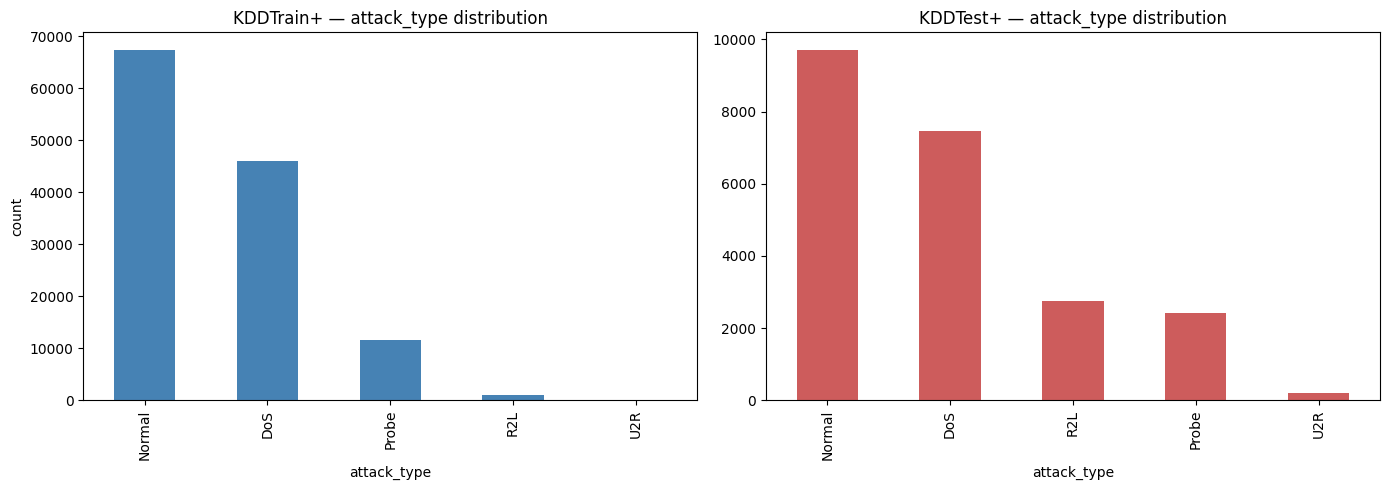

attack_type
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

attack_type
Normal    9711
DoS       7460
R2L       2752
Probe     2421
U2R        200
Name: count, dtype: int64

17 attack labels appear ONLY in KDDTest+, never in KDDTrain+:
['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

train["attack_type"].value_counts().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("KDDTrain+ — attack_type distribution")
axes[0].set_ylabel("count")

test["attack_type"].value_counts().plot(kind="bar", ax=axes[1], color="indianred")
axes[1].set_title("KDDTest+ — attack_type distribution")

plt.tight_layout()
plt.show()

print(train["attack_type"].value_counts())
print()
print(test["attack_type"].value_counts())

# Attack types that exist ONLY in the test set — direct evidence of the "unseen attack" property
train_labels = set(train["class"].unique())
test_labels = set(test["class"].unique())
test_only = test_labels - train_labels
print(f"\n{len(test_only)} attack labels appear ONLY in KDDTest+, never in KDDTrain+:")
print(sorted(test_only))

## 4. Preprocessing

- Categorical features (`protocol_type`, `service`, `flag`) → one-hot encoded. Fit the encoder on **train only** and transform test with `handle_unknown="ignore"` — NSL-KDD's `service` column has a few categories that appear only in the test set, and this avoids them silently crashing the pipeline or leaking test-set structure into training.
- Numeric features → scaled with `StandardScaler`, fit on train only.
- `difficulty_level` is dropped (benchmarking metadata, not a real traffic feature).

In [7]:
categorical_cols = ["protocol_type", "service", "flag"]
numeric_cols = [c for c in columns if c not in categorical_cols + ["class", "difficulty_level"]]

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder.fit(train[categorical_cols])

train_cat = pd.DataFrame(encoder.transform(train[categorical_cols]),
                          columns=encoder.get_feature_names_out(categorical_cols), index=train.index)
test_cat = pd.DataFrame(encoder.transform(test[categorical_cols]),
                         columns=encoder.get_feature_names_out(categorical_cols), index=test.index)

scaler = StandardScaler()
scaler.fit(train[numeric_cols])

train_num = pd.DataFrame(scaler.transform(train[numeric_cols]), columns=numeric_cols, index=train.index)
test_num = pd.DataFrame(scaler.transform(test[numeric_cols]), columns=numeric_cols, index=test.index)

X_train = pd.concat([train_num, train_cat], axis=1)
X_test = pd.concat([test_num, test_cat], axis=1)

y_train_binary = train["binary_target"]
y_test_binary = test["binary_target"]
y_train_multi = train["attack_type"]
y_test_multi = test["attack_type"]

# Keep raw (unscaled) values around too — purely for human-readable SHAP display later,
# never used for training/prediction, so no leakage risk.
test_raw_display = test[numeric_cols + categorical_cols].reset_index(drop=True)

print("X_train shape:", X_train.shape, " X_test shape:", X_test.shape)

X_train shape: (125973, 122)  X_test shape: (22544, 122)


## 5. Binary Classification — Normal vs Attack

Two numbers matter here, and they'll differ: **5-fold cross-validation on the training set** (the optimistic number most papers quote, ~99%) vs **evaluation on the real held-out KDDTest+** (the honest number — commonly 78–89% in published work, because KDDTest+ contains attack subtypes never seen in training). Report the KDDTest+ number as your actual result.

In [8]:
rf_binary = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(rf_binary, X_train, y_train_binary, cv=cv, scoring="accuracy")
print(f"5-fold CV accuracy on KDDTrain+ (optimistic): {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

rf_binary.fit(X_train, y_train_binary)
y_pred_binary = rf_binary.predict(X_test)

test_acc = accuracy_score(y_test_binary, y_pred_binary)
print(f"\nAccuracy on real held-out KDDTest+ (honest result): {test_acc:.4f}")
print(f"Gap between CV and real test accuracy: {cv_scores.mean() - test_acc:.4f}")
print("\n", classification_report(y_test_binary, y_pred_binary, target_names=["Normal","Attack"]))

5-fold CV accuracy on KDDTrain+ (optimistic): 0.9989 (+/- 0.0002)

Accuracy on real held-out KDDTest+ (honest result): 0.7677
Gap between CV and real test accuracy: 0.2312

               precision    recall  f1-score   support

      Normal       0.66      0.97      0.78      9711
      Attack       0.97      0.61      0.75     12833

    accuracy                           0.77     22544
   macro avg       0.81      0.79      0.77     22544
weighted avg       0.83      0.77      0.76     22544



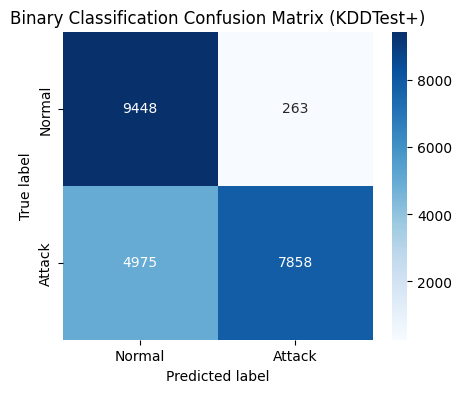

In [9]:
cm = confusion_matrix(y_test_binary, y_pred_binary)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal","Attack"], yticklabels=["Normal","Attack"])
plt.title("Binary Classification Confusion Matrix (KDDTest+)")
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.show()

### Grouped CV Setup

Each fold holds out whole attack types (mimics unseen attacks) while keeping both Normal and Attack rows. Used for hyperparameter search and threshold selection on training data only.

In [10]:
groups = train["class"].values.astype(object).copy()
nm = (train["class"] == "normal").values
groups[nm] = np.random.RandomState(42).randint(0, 8, nm.sum()).astype(str)  # split Normal into chunks

group_cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)

# candidate thresholds for the Normal/Attack decision
grid = np.r_[0.005, 0.01, 0.02, 0.03, np.arange(0.05, 0.96, 0.05)]

### XGBoost Hyperparameter Search — Grouped CV

Randomized search on the binary model, scored by balanced accuracy on the grouped folds. KDDTest+ is not used.

In [11]:
dist = {"max_depth": randint(3, 11), "n_estimators": randint(100, 400),
        "learning_rate": uniform(0.03, 0.27), "min_child_weight": randint(1, 10),
        "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.5, 0.5)}
search = RandomizedSearchCV(xgb.XGBClassifier(n_jobs=-1, random_state=42), dist, n_iter=15,
                            scoring="balanced_accuracy", cv=group_cv,
                            random_state=42, refit=False, verbose=1)
search.fit(X_train, y_train_binary, groups=groups)

best = {k: (int(v) if isinstance(v, (int, np.integer)) else float(v)) for k, v in search.best_params_.items()}
print("best params:", best)
print("grouped CV balanced accuracy:", round(search.best_score_, 4))

Fitting 4 folds for each of 15 candidates, totalling 60 fits
best params: {'colsample_bytree': 0.6404672548436904, 'learning_rate': 0.1765279424527271, 'max_depth': 3, 'min_child_weight': 1, 'n_estimators': 108, 'subsample': 0.908897907718663}
grouped CV balanced accuracy: 0.7996


### Tuned Binary Model — Threshold and KDDTest+ Result

The threshold is chosen on out-of-fold training predictions (maximum balanced accuracy), then the model is evaluated once on KDDTest+.

chosen threshold: 0.02
              precision    recall  f1-score   support

      Normal       0.83      0.94      0.88      9711
      Attack       0.95      0.86      0.90     12833

    accuracy                           0.89     22544
   macro avg       0.89      0.90      0.89     22544
weighted avg       0.90      0.89      0.89     22544



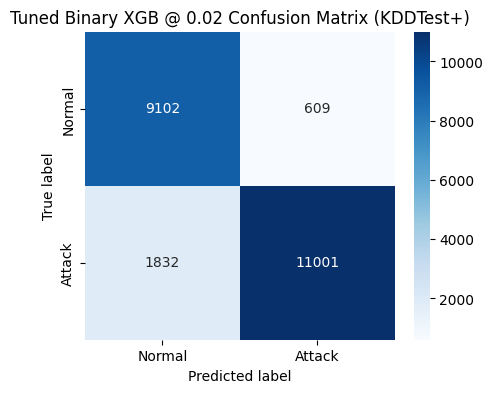

In [12]:
clf_t = xgb.XGBClassifier(**best, random_state=42, n_jobs=-1)

oof = cross_val_predict(clf_t, X_train, y_train_binary, groups=groups, cv=group_cv, method="predict_proba")[:, 1]
thr = round(float(grid[np.argmax([balanced_accuracy_score(y_train_binary, (oof >= t).astype(int)) for t in grid])]), 3)
print("chosen threshold:", thr)

clf_t.fit(X_train, y_train_binary)
pt = clf_t.predict_proba(X_test)[:, 1]
print(classification_report(y_test_binary, (pt >= thr).astype(int), target_names=["Normal", "Attack"]))

cm_t = confusion_matrix(y_test_binary, (pt >= thr).astype(int))
plt.figure(figsize=(5, 4))
sns.heatmap(cm_t, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"])
plt.title(f"Tuned Binary XGB @ {thr} Confusion Matrix (KDDTest+)")
plt.ylabel("True label"); plt.xlabel("Predicted label")
plt.show()

## 6. Multiclass Classification — Attack Type, with Moderate SMOTE

U2R has only 52 training samples and R2L has 995. SMOTE is applied to **the training set only** (never to test).

**SMOTE sizes are deliberately mild:** R2L 995 → 3,000 (~3x) and U2R 52 → 500 (~10x). Earlier values (R2L 10,000 / U2R 5,000, i.e. ~96x for U2R) made the model memorise synthetic points: train U2R precision 0.18 at recall 0.94, while test U2R recall stayed ~0.15. Normal, DoS and Probe are left untouched.

The XGBoost model is also shallower and regularized (`max_depth=4`, `min_child_weight`, `subsample`, `colsample_bytree`, `reg_lambda`), in line with the grouped-CV result for the binary model, where depth 3 won.

> **Known ceiling:** KDDTest+ has 17 attack types never seen in training, so R2L/U2R scores on test stay low whatever SMOTE does. Report that honestly.

In [13]:
print("Before SMOTE:")
print(y_train_multi.value_counts())

# Mild oversampling of the two tiny classes only. Others keep their exact counts.
smote_strategy = {
    "Normal": 67343,
    "DoS": 45927,
    "Probe": 11656,
    "R2L": 3000,
    "U2R": 500,
}

smote = SMOTE(sampling_strategy=smote_strategy, random_state=RANDOM_STATE, k_neighbors=5)
X_train_sm, y_train_multi_sm = smote.fit_resample(X_train, y_train_multi)

print("\nAfter SMOTE:")
print(y_train_multi_sm.value_counts())

Before SMOTE:
attack_type
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

After SMOTE:
attack_type
Normal    67343
DoS       45927
Probe     11656
R2L        3000
U2R         500
Name: count, dtype: int64


In [14]:
xgb_multi = xgb.XGBClassifier(
    n_estimators=200, max_depth=4, learning_rate=0.1,
    min_child_weight=5, subsample=0.8, colsample_bytree=0.7, reg_lambda=5,
    random_state=RANDOM_STATE, eval_metric="mlogloss", n_jobs=-1
)

le = LabelEncoder()
y_train_multi_enc = le.fit_transform(y_train_multi_sm)
y_test_multi_enc = le.transform(y_test_multi)

xgb_multi.fit(X_train_sm, y_train_multi_enc)
y_pred_multi_enc = xgb_multi.predict(X_test)
y_pred_multi = le.inverse_transform(y_pred_multi_enc)

print(classification_report(y_test_multi, y_pred_multi, target_names=le.classes_))

              precision    recall  f1-score   support

         DoS       0.96      0.84      0.90      7460
      Normal       0.67      0.97      0.80      9711
       Probe       0.83      0.62      0.71      2421
         R2L       0.98      0.06      0.11      2752
         U2R       0.76      0.10      0.17       200

    accuracy                           0.77     22544
   macro avg       0.84      0.52      0.54     22544
weighted avg       0.82      0.77      0.73     22544



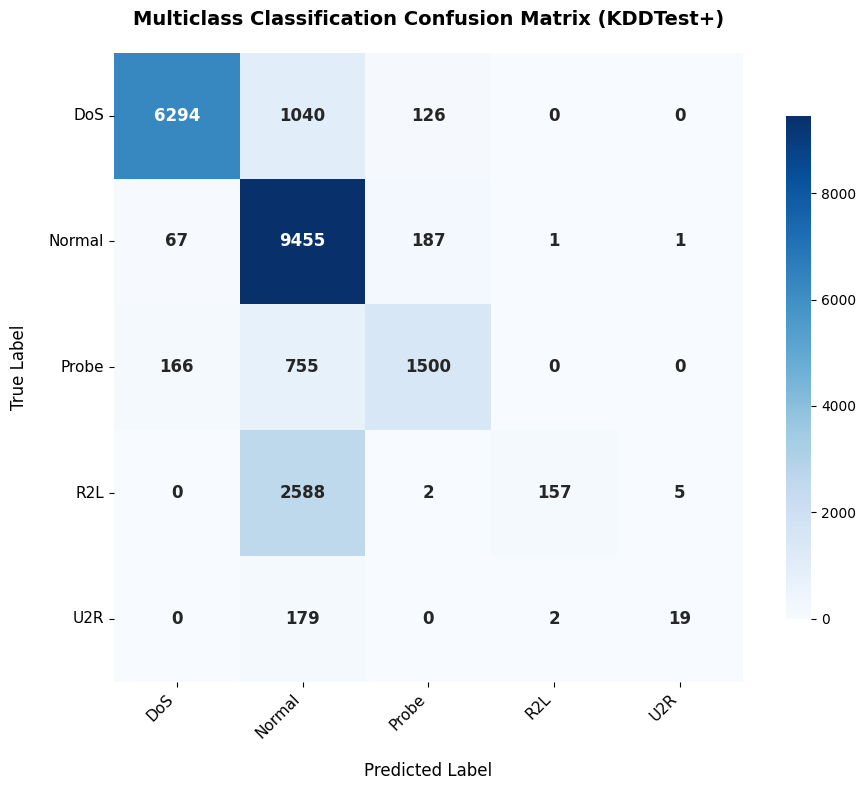


Per-class F1 (watch R2L / U2R specifically):
  DoS     : 0.9000
  Normal  : 0.7969
  Probe   : 0.7082
  R2L     : 0.1078
  U2R     : 0.1689


In [15]:
cm_multi = confusion_matrix(y_test_multi, y_pred_multi, labels=le.classes_)

# Set a larger figure size and use clear spacing to prevent overlapping numbers or labels
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_multi,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_,
    annot_kws={"size": 12, "weight": "bold"},  # Large, readable text inside boxes
    square=True,
    cbar_kws={"shrink": 0.8}
)

plt.title("Multiclass Classification Confusion Matrix (KDDTest+)", fontsize=14, pad=20, weight="bold")
plt.ylabel("True Label", fontsize=12, labelpad=15)
plt.xlabel("Predicted Label", fontsize=12, labelpad=15)

# Rotate labels slightly to ensure they have plenty of room
plt.xticks(rotation=45, ha="right", fontsize=11)
plt.yticks(rotation=0, fontsize=11)

plt.tight_layout()
plt.show()

# Per-class metrics isolated
print("\nPer-class F1 (watch R2L / U2R specifically):")
for cls, f1 in zip(le.classes_, f1_score(y_test_multi, y_pred_multi, labels=le.classes_, average=None)):
    print(f"  {cls:8s}: {f1:.4f}")

## 7. SHAP Explainability

For each flagged flow, show which of the input features pushed the model toward that prediction — this is the "why flagged" layer the case study is built around, not just a label.

shap_values shape: (500, 122, 5)

--- SHAP Summary (Top 10 Features) for Class: DoS ---


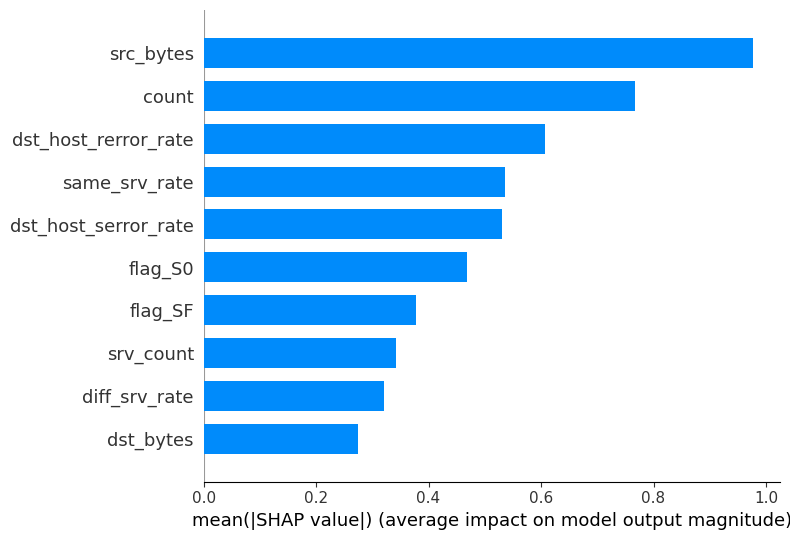


--- SHAP Summary (Top 10 Features) for Class: Probe ---


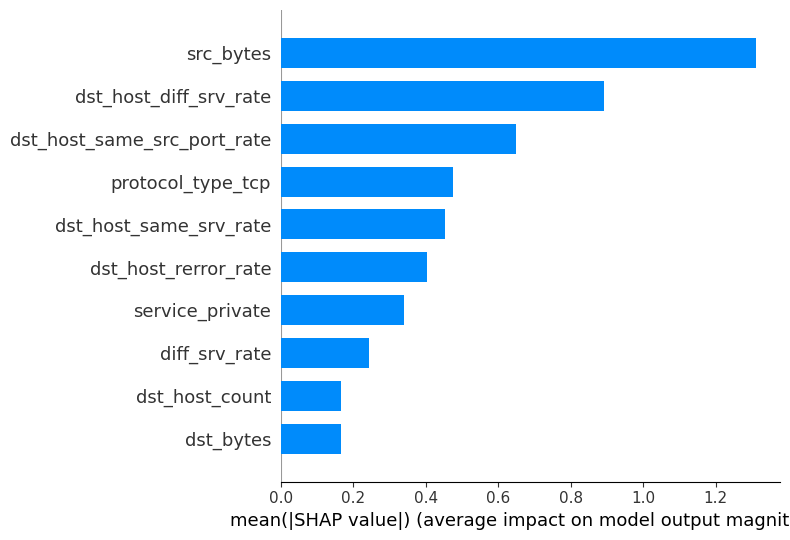


--- SHAP Summary (Top 10 Features) for Class: R2L ---


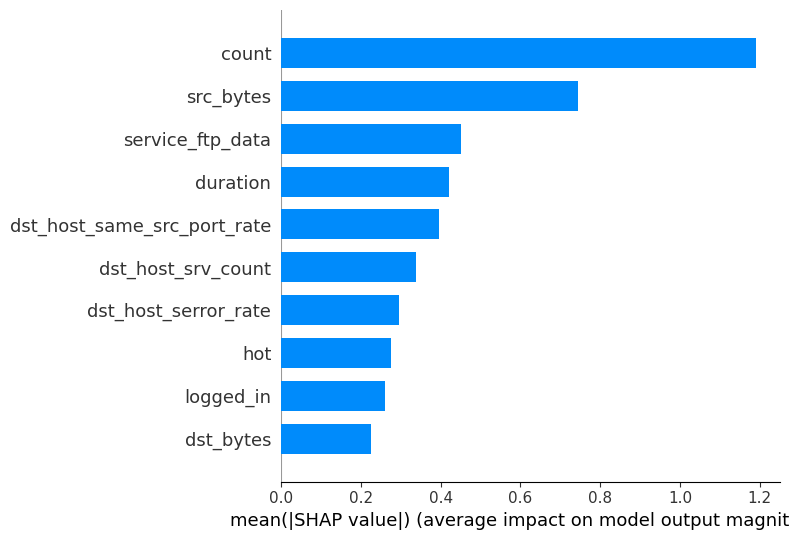


--- SHAP Summary (Top 10 Features) for Class: U2R ---


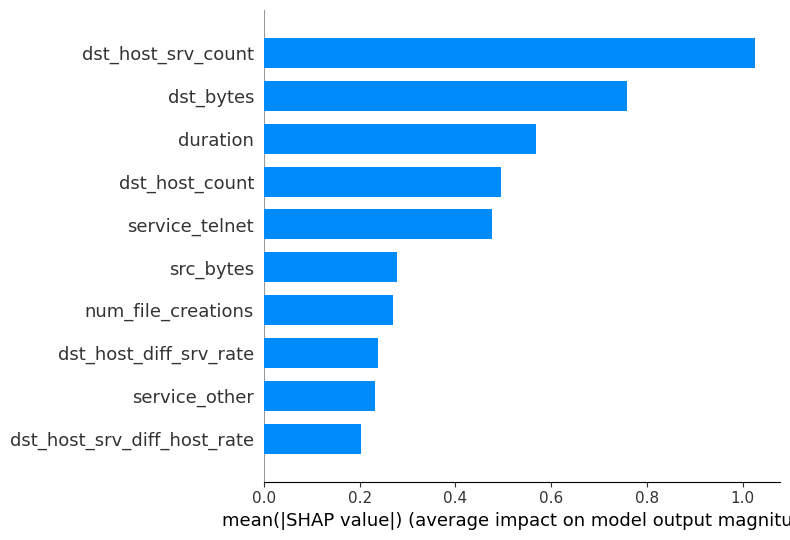

In [16]:
explainer = shap.TreeExplainer(xgb_multi)
shap_values = explainer.shap_values(X_test.iloc[:500])

print("shap_values shape:", shap_values.shape)

# Shorten the output by limiting to the top 10 features for each class
for i, cls in enumerate(le.classes_):
    if cls == "Normal":
        continue  # skip normal to save space, focusing only on attack categories
    print(f"\n--- SHAP Summary (Top 10 Features) for Class: {cls} ---")
    shap.summary_plot(shap_values[:, :, i], X_test.iloc[:500], max_display=10, plot_type="bar", show=True)

Sample index 0 — predicted: DoS


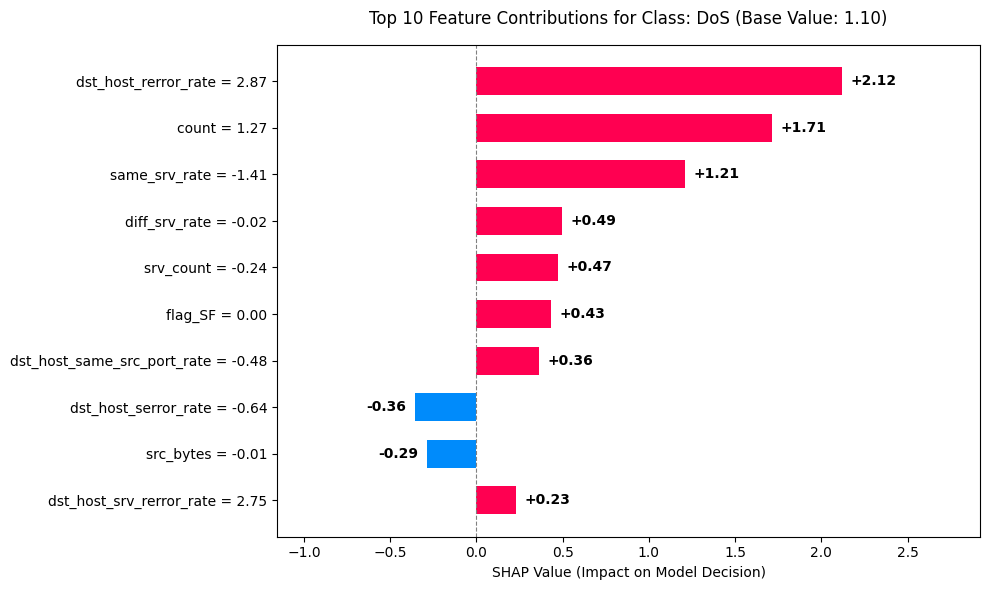

In [17]:
# Explain one specific flagged sample (first predicted-Attack row)
attack_idx = np.where(y_pred_multi != "Normal")[0][0]
sample = X_test.iloc[[attack_idx]]
pred_class = y_pred_multi[attack_idx]
pred_class_idx = list(le.classes_).index(pred_class)

print(f"Sample index {attack_idx} — predicted: {pred_class}")

sv = explainer.shap_values(sample)

# Extract SHAP values for the predicted class for this specific sample
sample_sv = sv[0, :, pred_class_idx]

# Identify the top 10 features with the highest absolute SHAP impact
top_indices = np.argsort(np.abs(sample_sv))[-10:]

filtered_sv = sample_sv[top_indices]
filtered_names = X_test.columns[top_indices]
filtered_values = X_test.iloc[attack_idx, top_indices]

# Combine names and actual values for clean labels
labels = [f"{name} = {val:.2f}" if isinstance(val, (int, float)) else f"{name} = {val}"
          for name, val in zip(filtered_names, filtered_values)]

# Plot a clean, spaced out horizontal bar chart to prevent any overlapping
plt.figure(figsize=(10, 6))
colors = ['#ff0051' if val > 0 else '#008bfb' for val in filtered_sv]
bars = plt.barh(labels, filtered_sv, color=colors, edgecolor='none', height=0.6)

# Add values to the end of the bars, adjusting alignment based on direction
for bar in bars:
    width = bar.get_width()
    if width >= 0:
        plt.text(
            width + 0.05,
            bar.get_y() + bar.get_height()/2,
            f"{width:+.2f}",
            va='center',
            ha='left',
            fontsize=10,
            weight='bold'
        )
    else:
        plt.text(
            width - 0.05,
            bar.get_y() + bar.get_height()/2,
            f"{width:+.2f}",
            va='center',
            ha='right',  # Align text to the right side of the coordinate so it doesn't overlap left labels
            fontsize=10,
            weight='bold'
        )

plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.title(f"Top 10 Feature Contributions for Class: {pred_class} (Base Value: {explainer.expected_value[pred_class_idx]:.2f})", fontsize=12, pad=15)
plt.xlabel("SHAP Value (Impact on Model Decision)", fontsize=10)
plt.xlim(min(filtered_sv) - 0.8, max(filtered_sv) + 0.8)  # Leave safety margins on both sides
plt.tight_layout()
plt.show()

## 7b. Raw Model Score (`predict_proba`)

A label alone ("DoS") doesn't say how strongly the model backs it. `predict_proba` gives a score for each of the 5 classes.

> **Problem:** the raw XGBoost score saturates. It sits at ~100% on many predictions, and it is nearly as high when the prediction is wrong (see the means printed below). That is **over-confidence**, so the raw number must not be shown as certainty.
>
> The app therefore shows two separate things: the **prediction** (the label) and a **calibrated `model_score`** (section 7c).

In [18]:
# Raw (uncalibrated) scores for the same sample explained above
proba = xgb_multi.predict_proba(sample)[0]
proba_breakdown = sorted(zip(le.classes_, proba), key=lambda x: -x[1])

print(f"Sample index {attack_idx} - predicted: {pred_class}\n")
print("Raw model scores (before calibration):")
for cls, p in proba_breakdown:
    marker = " <-- predicted" if cls == pred_class else ""
    print(f"  {cls:8s}: {p*100:5.1f}%{marker}")

# Whole test set: raw score = probability of whichever class was predicted
all_proba = xgb_multi.predict_proba(X_test)
raw_scores = all_proba.max(axis=1)

print(f"\nAcross all {len(raw_scores)} test samples (raw scores):")
print(f"  Mean raw score on CORRECT predictions:   {raw_scores[y_pred_multi == y_test_multi.values].mean()*100:.1f}%")
print(f"  Mean raw score on INCORRECT predictions: {raw_scores[y_pred_multi != y_test_multi.values].mean()*100:.1f}%")
print(f"  Wrong predictions scored >= 99%:         {(raw_scores[y_pred_multi != y_test_multi.values] >= 0.99).mean()*100:.1f}%")

Sample index 0 - predicted: DoS

Raw model scores (before calibration):
  DoS     : 100.0% <-- predicted
  Probe   :   0.0%
  Normal  :   0.0%
  R2L     :   0.0%
  U2R     :   0.0%

Across all 22544 test samples (raw scores):
  Mean raw score on CORRECT predictions:   98.7%
  Mean raw score on INCORRECT predictions: 92.5%
  Wrong predictions scored >= 99%:         47.3%


## 7c. Calibrating the Model Score (temperature scaling)

One number `TEMPERATURE` softens the raw scores so they stop saturating at 100%. It is fitted on **out-of-fold training predictions where whole attack names are held out**, which imitates unseen attacks, so the score learns how wrong the model can be on them.

- It does **not** change any predicted label (the ranking of classes is unchanged), so accuracy and F1 stay exactly the same.
- `LOW_CONF_THRESHOLD = 0.6`: below this the app shows a **Low confidence** badge. The table printed below shows what each threshold flags on KDDTest+.
- Backend needs 3 numbers: binary threshold, `TEMPERATURE`, `LOW_CONF_THRESHOLD` (saved in section 9).

In [19]:
from scipy.optimize import minimize_scalar
import time

def temp_scale(P, T):
    """Soften class probabilities with temperature T (T > 1 = less extreme). Labels never change."""
    L = np.log(np.clip(P, 1e-12, 1.0)) / T
    L = L - L.max(axis=1, keepdims=True)
    E = np.exp(L)
    return E / E.sum(axis=1, keepdims=True)

# 1) Out-of-fold multiclass probabilities; whole attack names are held out in every fold
t0 = time.time()
y_enc = le.transform(y_train_multi)
oof_P = np.zeros((len(X_train), len(le.classes_)))
for fold, (tr, va) in enumerate(group_cv.split(X_train, y_enc, groups), 1):
    Xr, yr = SMOTE(sampling_strategy={"R2L": 3000, "U2R": 500},
                   random_state=RANDOM_STATE, k_neighbors=5).fit_resample(
                       X_train.iloc[tr], y_train_multi.iloc[tr])
    le_f = LabelEncoder().fit(yr)
    m = xgb.XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1,
                          min_child_weight=5, subsample=0.8, colsample_bytree=0.7, reg_lambda=5,
                          random_state=RANDOM_STATE, eval_metric="mlogloss", n_jobs=-1)
    m.fit(Xr, le_f.transform(yr))
    oof_P[np.ix_(va, le.transform(le_f.classes_))] = m.predict_proba(X_train.iloc[va])
    print(f"fold {fold}/4 done ({time.time() - t0:.0f}s)")

# 2) Fit the single temperature on those out-of-fold probabilities
nll = lambda T: -np.log(np.clip(temp_scale(oof_P, T)[np.arange(len(y_enc)), y_enc], 1e-12, 1)).mean()
TEMPERATURE = float(minimize_scalar(nll, bounds=(0.5, 30), method="bounded").x)
LOW_CONF_THRESHOLD = 0.6
print(f"\nTEMPERATURE = {TEMPERATURE:.2f}   (out-of-fold log-loss {nll(1.0):.3f} -> {nll(TEMPERATURE):.3f})")

# 3) Effect on KDDTest+ (labels are identical, only the score changes)
def ece(score, correct, bins=10):
    edges, e = np.linspace(0, 1, bins + 1), 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        k = (score > lo) & (score <= hi)
        if k.any():
            e += k.mean() * abs(correct[k].mean() - score[k].mean())
    return e

raw_P = xgb_multi.predict_proba(X_test)
cal_P = temp_scale(raw_P, TEMPERATURE)
correct = raw_P.argmax(axis=1) == y_test_multi_enc
print("\nscore       mean(right)  mean(wrong)  wrong>=99%  right>=99%   ECE")
for name, P in [("raw", raw_P), ("calibrated", cal_P)]:
    s = P.max(axis=1)
    print(f"{name:10s}  {s[correct].mean():10.3f}  {s[~correct].mean():11.3f}  "
          f"{(s[~correct] >= .99).mean():9.1%}  {(s[correct] >= .99).mean():10.1%}  {ece(s, correct):.3f}")

print("\nLow-confidence badge threshold (calibrated score below it):")
s = cal_P.max(axis=1)
for th in (0.5, 0.6, 0.7, 0.8):
    f = s < th
    print(f"  < {th}: flags {f.mean():5.1%} of rows | correct among flagged {correct[f].mean():.1%} | correct among the rest {correct[~f].mean():.1%}")

fold 1/4 done (27s)
fold 2/4 done (40s)
fold 3/4 done (65s)
fold 4/4 done (90s)

TEMPERATURE = 4.06   (out-of-fold log-loss 2.349 -> 1.022)

score       mean(right)  mean(wrong)  wrong>=99%  right>=99%   ECE
raw              0.987        0.925      47.3%       92.7%  0.201
calibrated       0.776        0.573       0.0%        0.0%  0.125

Low-confidence badge threshold (calibrated score below it):
  < 0.5: flags  9.3% of rows | correct among flagged 29.8% | correct among the rest 82.2%
  < 0.6: flags 18.5% of rows | correct among flagged 31.9% | correct among the rest 87.6%
  < 0.7: flags 32.7% of rows | correct among flagged 43.2% | correct among the rest 93.9%
  < 0.8: flags 51.4% of rows | correct among flagged 55.8% | correct among the rest 99.9%


## 8. Final Prediction Pipeline (what the app will use)

- The **binary tuned model** decides Normal vs Attack, using the threshold chosen on grouped out-of-fold training data.
- The **multiclass model** only picks the attack type. If the binary model flags an attack but the multiclass model's top class is Normal, the best *attack* class is shown instead.
- Preprocessing uses the column names stored inside the fitted `scaler` and `encoder` (`feature_names_in_`), so the backend needs only the saved `.pkl` files and three numbers.
- The app output is split in two on purpose:
  - **`prediction`** - the label (Normal / DoS / Probe / R2L / U2R).
  - **`model_score`** - the *calibrated* score of that label (section 7c). It is a score from the model, not a probability of being right.
- `low_confidence` is True when `model_score < LOW_CONF_THRESHOLD`; `top3` lists the shown label first, then the next two highest classes.

In [20]:
THRESHOLD = thr    # binary threshold  | hardcode in the backend
# TEMPERATURE and LOW_CONF_THRESHOLD come from section 7c | hardcode in the backend too

def predict_traffic(raw_df, with_top3=True):
    """raw_df: DataFrame with the raw feature columns (same names as KDDTest+, without 'class' / 'difficulty_level')."""
    num_cols = list(scaler.feature_names_in_)
    cat_cols = list(encoder.feature_names_in_)

    num = pd.DataFrame(scaler.transform(raw_df[num_cols]), columns=num_cols, index=raw_df.index)
    cat = pd.DataFrame(encoder.transform(raw_df[cat_cols]),
                       columns=encoder.get_feature_names_out(cat_cols), index=raw_df.index)
    X = pd.concat([num, cat], axis=1)

    p_attack = clf_t.predict_proba(X)[:, 1]
    proba = temp_scale(xgb_multi.predict_proba(X), TEMPERATURE)     # calibrated, labels unchanged
    normal_idx = list(le.classes_).index("Normal")

    is_attack = p_attack >= THRESHOLD
    attack_only = proba.copy()
    attack_only[:, normal_idx] = -1                      # best ATTACK class
    pred_idx = np.where(is_attack, attack_only.argmax(axis=1), normal_idx)
    model_score = proba[np.arange(len(proba)), pred_idx]

    result = pd.DataFrame({
        "prediction": le.classes_[pred_idx],
        "is_attack": is_attack,
        "attack_score": p_attack,
        "model_score": model_score,
        "low_confidence": model_score < LOW_CONF_THRESHOLD,
    }, index=raw_df.index)

    if with_top3:   # shown label first, then the next two highest classes
        top3 = []
        for r in range(len(proba)):
            others = [j for j in np.argsort(-proba[r]) if j != pred_idx[r]][:2]
            top3.append([{"class": str(le.classes_[j]), "score": round(float(proba[r, j]), 4)}
                         for j in [pred_idx[r]] + others])
        result["top3"] = top3
    return result

Binary decision identical to the tuned model above: True

Binary (Normal vs Attack):
              precision    recall  f1-score   support

      Normal       0.83      0.94      0.88      9711
      Attack       0.95      0.86      0.90     12833

    accuracy                           0.89     22544
   macro avg       0.89      0.90      0.89     22544
weighted avg       0.90      0.89      0.89     22544

Multiclass (final labels):
              precision    recall  f1-score   support

         DoS       0.95      0.87      0.91      7460
      Normal       0.83      0.94      0.88      9711
       Probe       0.57      0.91      0.70      2421
         R2L       0.91      0.30      0.45      2752
         U2R       0.57      0.20      0.29       200

    accuracy                           0.83     22544
   macro avg       0.77      0.64      0.65     22544
weighted avg       0.85      0.83      0.81     22544



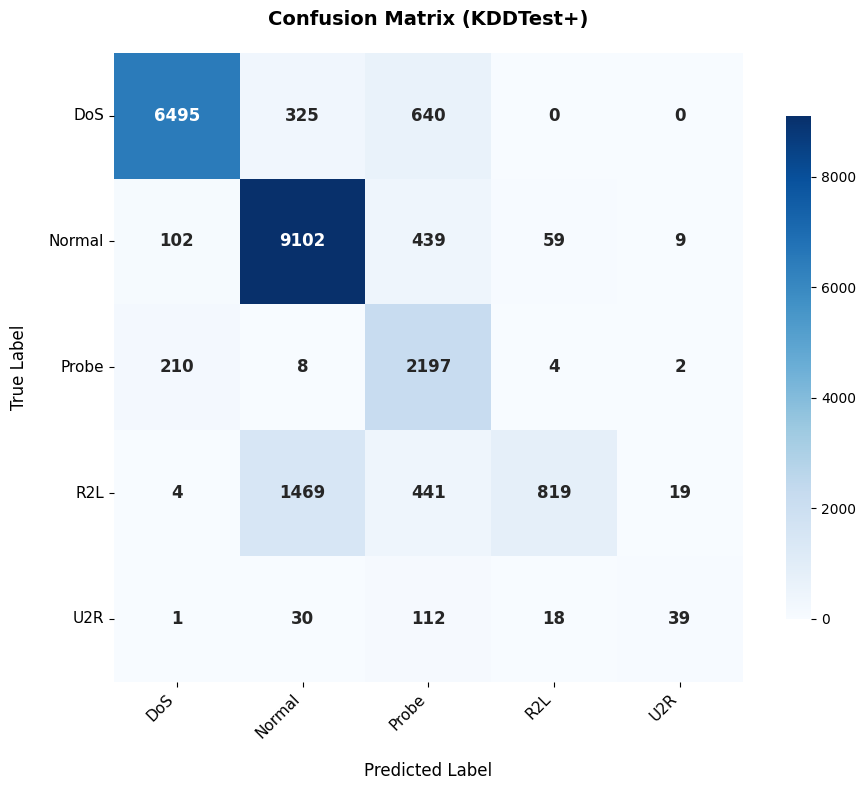

  prediction  is_attack  attack_score  model_score  low_confidence  \
0        DoS       True      0.999798     0.833875           False   
1        DoS       True      0.999835     0.746918           False   
2     Normal      False      0.018129     0.655520           False   
3      Probe       True      0.988416     0.666418           False   
4      Probe       True      0.180959     0.283449            True   

                                                top3  
0  [{'class': 'DoS', 'score': 0.8339}, {'class': ...  
1  [{'class': 'DoS', 'score': 0.7469}, {'class': ...  
2  [{'class': 'Normal', 'score': 0.6555}, {'class...  
3  [{'class': 'Probe', 'score': 0.6664}, {'class'...  
4  [{'class': 'Probe', 'score': 0.2834}, {'class'...  

Low-confidence badge on 21.4% of KDDTest+ rows


In [21]:
# Evaluate the complete pipeline on KDDTest+ (raw rows in, final labels out)
raw_cols = list(scaler.feature_names_in_) + list(encoder.feature_names_in_)
out = predict_traffic(test[raw_cols])

print("Binary decision identical to the tuned model above:", np.array_equal(out["is_attack"].values, pt >= thr))
print("\nBinary (Normal vs Attack):")
print(classification_report(y_test_binary, out["is_attack"].astype(int), target_names=["Normal", "Attack"]))

print("Multiclass (final labels):")
print(classification_report(y_test_multi, out["prediction"], target_names=le.classes_))

cm_final = confusion_matrix(y_test_multi, out["prediction"], labels=le.classes_)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_final, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_,
            annot_kws={"size": 12, "weight": "bold"}, square=True, cbar_kws={"shrink": 0.8})
plt.title("Confusion Matrix (KDDTest+)", fontsize=14, pad=20, weight="bold")
plt.ylabel("True Label", fontsize=12, labelpad=15); plt.xlabel("Predicted Label", fontsize=12, labelpad=15)
plt.xticks(rotation=45, ha="right", fontsize=11); plt.yticks(rotation=0, fontsize=11)
plt.tight_layout(); plt.show()

print(out.head())
print(f"\nLow-confidence badge on {out['low_confidence'].mean():.1%} of KDDTest+ rows")

### 10. Overfitting Analysis
Let's evaluate the final pipeline's performance on both the **Training Set** and the **Test Set** to see if the model has overfit.

In [22]:
# Get predictions on the training data
train_raw_cols = list(scaler.feature_names_in_) + list(encoder.feature_names_in_)
train_out = predict_traffic(train[train_raw_cols])

print("=== TRAINING SET PERFORMANCE ===")
print(classification_report(y_train_multi, train_out["prediction"], target_names=le.classes_))

print("\n=== TEST SET PERFORMANCE ===")
print(classification_report(y_test_multi, out["prediction"], target_names=le.classes_))

# Calculate and display the F1-score gap for each class
train_f1 = f1_score(y_train_multi, train_out["prediction"], labels=le.classes_, average=None)
test_f1 = f1_score(y_test_multi, out["prediction"], labels=le.classes_, average=None)

print("\n=== F1-Score Generalization Gap (Train - Test) ===")
for cls, tr_f, te_f in zip(le.classes_, train_f1, test_f1):
    gap = tr_f - te_f
    print(f"  {cls:8s} | Train F1: {tr_f:.4f} | Test F1: {te_f:.4f} | Gap: {gap:+.4f}")


=== TRAINING SET PERFORMANCE ===
              precision    recall  f1-score   support

         DoS       0.99      1.00      1.00     45927
      Normal       1.00      0.95      0.97     67343
       Probe       0.87      1.00      0.93     11656
         R2L       0.42      0.99      0.59       995
         U2R       0.27      0.94      0.42        52

    accuracy                           0.97    125973
   macro avg       0.71      0.98      0.78    125973
weighted avg       0.98      0.97      0.97    125973


=== TEST SET PERFORMANCE ===
              precision    recall  f1-score   support

         DoS       0.95      0.87      0.91      7460
      Normal       0.83      0.94      0.88      9711
       Probe       0.57      0.91      0.70      2421
         R2L       0.91      0.30      0.45      2752
         U2R       0.57      0.20      0.29       200

    accuracy                           0.83     22544
   macro avg       0.77      0.64      0.65     22544
weighted avg  

### 10b. Why the train-test gap is not overfitting

Scored on rows held out from KDDTrain+ itself, accuracy is about the same as on the training rows (~99.9%), so the model is not memorising. The gap appears only on **KDDTest+**, which is a different distribution:

- 509 R2L rows (`snmpguess`, `snmpgetattack`) and 133 of 200 U2R rows (`httptunnel`) belong to attack names that never appear in KDDTrain+.
- 1,231 R2L rows are `guess_passwd`, which has only 53 training examples and looks like an ordinary login, so most of them are flagged Normal.

This distribution shift, not model size or SMOTE, limits the R2L/U2R scores. Oversampling cannot recover attacks the model has never seen. Report both numbers: in-distribution accuracy and KDDTest+ accuracy.

In [23]:
from sklearn.model_selection import train_test_split

# Same recipe as the final multiclass model, scored on rows held out from KDDTrain+ itself
Xa_tr, Xa_va, ya_tr, ya_va = train_test_split(
    X_train, y_train_multi, test_size=0.2, stratify=y_train_multi, random_state=RANDOM_STATE)

Xr, yr = SMOTE(sampling_strategy={"R2L": 2400, "U2R": 400},
               random_state=RANDOM_STATE, k_neighbors=5).fit_resample(Xa_tr, ya_tr)
le_chk = LabelEncoder().fit(yr)
m_chk = xgb.XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, min_child_weight=5,
                          subsample=0.8, colsample_bytree=0.7, reg_lambda=5,
                          random_state=RANDOM_STATE, eval_metric="mlogloss", n_jobs=-1)
m_chk.fit(Xr, le_chk.transform(yr))

acc_tr = accuracy_score(ya_tr, le_chk.inverse_transform(m_chk.predict(Xa_tr)))
acc_va = accuracy_score(ya_va, le_chk.inverse_transform(m_chk.predict(Xa_va)))
acc_te = accuracy_score(y_test_multi, le_chk.inverse_transform(m_chk.predict(X_test)))
print(f"accuracy on training rows (80%)            : {acc_tr:.4f}")
print(f"accuracy on held-out KDDTrain+ rows (20%)  : {acc_va:.4f}   <- same distribution")
print(f"accuracy on KDDTest+ (type-only model)     : {acc_te:.4f}   <- distribution shift")
print(f"overfitting gap (train - held-out)         : {acc_tr - acc_va:+.4f}")

accuracy on training rows (80%)            : 0.9994
accuracy on held-out KDDTrain+ rows (20%)  : 0.9988   <- same distribution
accuracy on KDDTest+ (type-only model)     : 0.7778   <- distribution shift
overfitting gap (train - held-out)         : +0.0007


### 8b. Demo Presets for the App

Builds `presets.csv` (20 rows from KDDTest+): per class, 3 rows the final pipeline gets right and 1 it gets wrong. Columns: the 41 raw features, the specific attack name (`class`) and the category (`attack_type`). Predictions are not stored — the app runs the live model on each row.

In [24]:
feature_cols = [c for c in columns if c not in ("class", "difficulty_level")]

t = test.copy()
t["correct"] = (out["prediction"].values == t["attack_type"].values)

parts = []
for cls in le.classes_:
    sub = t[t["attack_type"] == cls]
    right, wrong = sub[sub["correct"]], sub[~sub["correct"]]
    parts.append(right.sample(min(3, len(right)), random_state=42))   # correct examples
    parts.append(wrong.sample(min(1, len(wrong)), random_state=42))   # one wrong example

presets = pd.concat(parts)[feature_cols + ["class", "attack_type"]].reset_index(drop=True)
presets.to_csv("presets.csv", index=False)

print("rows:", len(presets), "| columns:", presets.shape[1])
print(presets["attack_type"].value_counts())
print(presets[["protocol_type", "service", "src_bytes", "class", "attack_type"]])

from google.colab import files
files.download("presets.csv")

rows: 20 | columns: 43
attack_type
DoS       4
Normal    4
Probe     4
R2L       4
U2R       4
Name: count, dtype: int64
   protocol_type   service  src_bytes            class attack_type
0           icmp     ecr_i       1032            smurf         DoS
1            tcp   private          0          neptune         DoS
2            tcp   private          0          neptune         DoS
3            tcp      smtp       2599         mailbomb         DoS
4            tcp      http        247           normal      Normal
5            tcp      http        311           normal      Normal
6            tcp      http        268           normal      Normal
7            tcp  ftp_data         22           normal      Normal
8            tcp    telnet          0            mscan       Probe
9           icmp     eco_i         20            saint       Probe
10           tcp   private          0            saint       Probe
11           tcp     pop_3          0            mscan       Probe
12      

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Save Model Artifacts

These are what the FastAPI backend (Part 2) loads to serve predictions — the encoder and scaler must be saved too, since new single-sample inputs need the exact same preprocessing applied before they reach the model.

In [25]:
import json

joblib.dump(clf_t, "xgb_binary_tuned.pkl")
joblib.dump(xgb_multi, "xgb_multi_model.pkl")
joblib.dump(encoder, "onehot_encoder.pkl")
joblib.dump(scaler, "standard_scaler.pkl")
joblib.dump(le, "label_encoder.pkl")

# The three numbers the backend needs, in one file
config = {"binary_threshold": float(thr),
          "temperature": float(TEMPERATURE),
          "low_confidence_threshold": float(LOW_CONF_THRESHOLD),
          "class_order": [str(c) for c in le.classes_]}
with open("pipeline_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Saved: xgb_binary_tuned.pkl, xgb_multi_model.pkl, onehot_encoder.pkl, standard_scaler.pkl, label_encoder.pkl, pipeline_config.json")
print(config)

# In Colab, download them to your machine:
from google.colab import files
for f in ["xgb_binary_tuned.pkl", "xgb_multi_model.pkl", "onehot_encoder.pkl",
          "standard_scaler.pkl", "label_encoder.pkl", "pipeline_config.json"]:
    files.download(f)

Saved: xgb_binary_tuned.pkl, xgb_multi_model.pkl, onehot_encoder.pkl, standard_scaler.pkl, label_encoder.pkl, pipeline_config.json
{'binary_threshold': 0.02, 'temperature': 4.063503007348509, 'low_confidence_threshold': 0.6, 'class_order': ['DoS', 'Normal', 'Probe', 'R2L', 'U2R']}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (3 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Export for the App

Everything the backend and dashboard need beyond the model files:

- **`feature_defaults.json`** - median/mode values for the 35 auto-filled features (manual mode) and the valid values of `protocol_type`, `service`, `flag` for the form dropdowns.
- **`eval_report.json`** + **`test_predictions.csv`** - confusion matrices, per-class metrics, ROC-AUC and the per-row test predictions, so the dashboard loads them from files instead of recomputing.

Manual mode only knows 6 of the 41 features, so its result is a rough demo, and the app must say so. Preset mode (real KDDTest+ rows) is the scientifically valid result.

In [26]:
p_attack_test = clf_t.predict_proba(X_test)[:, 1]
print(f"Binary ROC-AUC          : {roc_auc_score(y_test_binary, p_attack_test):.4f}")
print(f"Binary average precision: {average_precision_score(y_test_binary, p_attack_test):.4f}")

Binary ROC-AUC          : 0.9610
Binary average precision: 0.9636


In [27]:
feature_cols = [c for c in columns if c not in ("class", "difficulty_level")]
num_cols = list(scaler.feature_names_in_)
cat_cols = list(encoder.feature_names_in_)

defaults = {c: float(train[c].median()) for c in num_cols}            # numeric -> KDDTrain+ median
defaults.update({c: str(train[c].mode()[0]) for c in cat_cols})       # categorical -> KDDTrain+ mode

feature_defaults = {
    "manual_fields": ["protocol_type", "service", "flag", "duration", "src_bytes", "dst_bytes"],
    "defaults": defaults,                                              # backend overrides the 6 manual fields
    "categories": {c: [str(v) for v in cats] for c, cats in zip(cat_cols, encoder.categories_)},
    "feature_order": feature_cols,
}
with open("feature_defaults.json", "w") as f:
    json.dump(feature_defaults, f, indent=2)
print("manual fields:", feature_defaults["manual_fields"])
print({k: len(v) for k, v in feature_defaults["categories"].items()}, "categories per dropdown")

# Sanity check of manual mode: typical web request, everything else auto-filled
demo = dict(defaults)
demo.update({"protocol_type": "tcp", "service": "http", "flag": "SF",
             "duration": 0, "src_bytes": 232, "dst_bytes": 8153})
demo_out = predict_traffic(pd.DataFrame([demo])[feature_cols])
print(demo_out.drop(columns="top3").to_string(index=False))
print(demo_out["top3"].iloc[0])

manual fields: ['protocol_type', 'service', 'flag', 'duration', 'src_bytes', 'dst_bytes']
{'protocol_type': 3, 'service': 70, 'flag': 11} categories per dropdown
prediction  is_attack  attack_score  model_score  low_confidence
    Normal      False      0.001937     0.732401           False
[{'class': 'Normal', 'score': 0.7324}, {'class': 'DoS', 'score': 0.0792}, {'class': 'R2L', 'score': 0.0707}]


In [28]:
labels = list(le.classes_)
y_true = test["attack_type"].values
y_hat = out["prediction"].values
bin_hat = out["is_attack"].astype(int).values

rep = classification_report(y_true, y_hat, labels=labels, output_dict=True, zero_division=0)
eval_report = {
    "classes": labels,
    "multiclass": {
        "accuracy": float(accuracy_score(y_true, y_hat)),
        "macro_f1": float(f1_score(y_true, y_hat, average="macro")),
        "per_class": {c: {k: float(rep[c][k]) for k in ("precision", "recall", "f1-score", "support")} for c in labels},
        "confusion_matrix": confusion_matrix(y_true, y_hat, labels=labels).tolist(),
    },
    "binary": {
        "labels": ["Normal", "Attack"],
        "accuracy": float(accuracy_score(y_test_binary, bin_hat)),
        "roc_auc": float(roc_auc_score(y_test_binary, out["attack_score"])),
        "confusion_matrix": confusion_matrix(y_test_binary, bin_hat).tolist(),
    },
    "calibration": {"temperature": float(TEMPERATURE),
                    "low_confidence_threshold": float(LOW_CONF_THRESHOLD),
                    "low_confidence_share": float(out["low_confidence"].mean())},
    "dataset": {"train_rows": int(len(train)), "test_rows": int(len(test))},
}
with open("eval_report.json", "w") as f:
    json.dump(eval_report, f, indent=2)

pred_df = pd.DataFrame({
    "attack_name": test["class"].values, "true_label": y_true, "prediction": y_hat,
    "correct": y_hat == y_true, "model_score": out["model_score"].round(4).values,
    "low_confidence": out["low_confidence"].values, "attack_score": out["attack_score"].round(4).values,
    "top3": [json.dumps(t) for t in out["top3"]],
})
pred_df.to_csv("test_predictions.csv", index=False)

print(f"eval_report.json saved | test_predictions.csv saved: {len(pred_df)} rows")
print(f"multiclass accuracy {eval_report['multiclass']['accuracy']:.4f} | macro-F1 {eval_report['multiclass']['macro_f1']:.4f} | binary ROC-AUC {eval_report['binary']['roc_auc']:.4f}")

# In Colab, download them to your machine:
from google.colab import files
for f in ["feature_defaults.json", "eval_report.json", "test_predictions.csv"]:
    files.download(f)

eval_report.json saved | test_predictions.csv saved: 22544 rows
multiclass accuracy 0.8274 | macro-F1 0.6467 | binary ROC-AUC 0.9610


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>